# 04 — Comparação da CNN leve com a CNN residual
As duas rodadas usam a mesma divisão estratificada de 40.000 imagens de treino e 10.000 de validação, a mesma semente, o mesmo aumento de dados e orçamento de oito épocas. A variante residual adiciona quatro blocos com conexões de atalho. A arquitetura também muda onde o pooling e o dropout são aplicados.

Cada checkpoint foi selecionado pela menor perda de validação da sua rodada. As métricas finais usam inferência nos dois conjuntos. O lote oficial de teste fica reservado para a avaliação final.

In [1]:
import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent

reports = root / 'reports'
runs = {'CNN leve': reports, 'CNN residual': reports / 'residual_cpu'}
metadata = {
    name: json.loads((folder / 'run_metadata.json').read_text(encoding='utf-8'))
    for name, folder in runs.items()
}
with (
    np.load(root / 'data/processed/split_indices.npz') as baseline_split,
    np.load(root / 'data/processed/residual_cpu/split_indices.npz') as residual_split,
):
    for key in ('train_idx', 'val_idx'):
        np.testing.assert_array_equal(baseline_split[key], residual_split[key])

display(pd.DataFrame.from_dict({
    name: {
        'Parâmetros': run['model_parameters'],
        'Épocas concluídas': len(pd.read_csv(runs[name] / 'history.csv')),
        'Época selecionada': run['best_epoch'],
    }
    for name, run in metadata.items()
}, orient='index'))

,Parâmetros,Épocas concluídas,Época selecionada
CNN leve,82026,8,7
CNN residual,622442,8,8


## Precision, Recall, F1 e acurácia em inferência

In [2]:
metric_names = {
    'accuracy': 'Acurácia',
    'precision_macro': 'Precision macro',
    'recall_macro': 'Recall macro',
    'f1_macro': 'F1 macro',
}
scores = {}
for name, folder in runs.items():
    for split, filename in [('Treino', 'train_metrics.json'), ('Validação', 'validation_metrics.json')]:
        metrics = json.loads((folder / filename).read_text(encoding='utf-8'))
        scores[name, split] = {label: metrics[key] * 100 for key, label in metric_names.items()}
comparison = pd.DataFrame(scores)
comparison['Diferença na validação (p.p.)', 'Residual − leve'] = (
    comparison['CNN residual', 'Validação'] - comparison['CNN leve', 'Validação']
)
display(comparison.round(2))

CNN leve           CNN residual            \
                  Treino Validação       Treino Validação   
Acurácia           68.24     66.97        74.07     71.84   
Precision macro    68.54     67.33        77.37     75.15   
Recall macro       68.24     66.97        74.07     71.84   
F1 macro           67.38     66.17        73.83     71.42   

                Diferença na validação (p.p.)  
                              Residual − leve  
Acurácia                                 4.87  
Precision macro                          7.82  
Recall macro                             4.87  
F1 macro                                 5.25

## Curvas por época
A linha tracejada indica o checkpoint selecionado em cada rodada. A perda inclui a penalidade L2 da arquitetura de cada modelo.

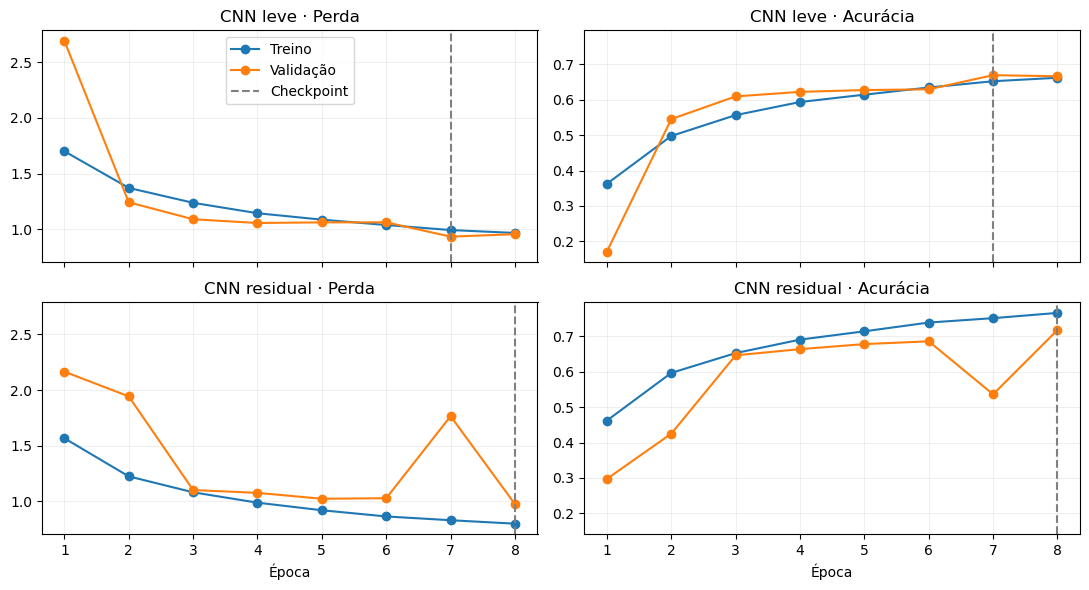

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey='col')
for row, (name, folder) in enumerate(runs.items()):
    history = pd.read_csv(folder / 'history.csv')
    epochs = range(1, len(history) + 1)
    for ax, metric, label in zip(axes[row], ('loss', 'accuracy'), ('Perda', 'Acurácia')):
        ax.plot(epochs, history[metric], marker='o', label='Treino')
        ax.plot(epochs, history[f'val_{metric}'], marker='o', label='Validação')
        ax.axvline(metadata[name]['best_epoch'], color='gray', ls='--', label='Checkpoint')
        ax.set(title=f'{name} · {label}', xticks=list(epochs))
        ax.grid(alpha=0.2)
for ax in axes[1]:
    ax.set_xlabel('Época')
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## Métricas por classe na validação

In [4]:
class_columns = ['precision', 'recall', 'f1-score']
by_class = {
    name: pd.read_csv(folder / 'validation_classification_report.csv', index_col=0)
    .drop(index=['accuracy', 'macro avg', 'weighted avg'])[class_columns]
    for name, folder in runs.items()
}
classes = pd.concat(by_class, axis=1) * 100
classes['Diferença (p.p.)', 'F1'] = classes['CNN residual', 'f1-score'] - classes['CNN leve', 'f1-score']
display(classes.sort_values(('CNN residual', 'f1-score')).round(2))

CNN leve                 CNN residual                  \
           precision recall f1-score    precision recall f1-score   
bird           58.75   50.0    54.02        86.86   35.7    50.60   
cat            52.23   30.5    38.51        61.40   48.2    54.01   
dog            51.06   62.9    56.36        61.64   68.6    64.93   
frog           67.70   78.6    72.74        50.97   94.8    66.29   
deer           72.85   48.3    58.09        63.56   71.7    67.39   
horse          66.10   73.5    69.60        88.08   64.3    74.34   
airplane       58.28   84.1    68.85        73.67   80.3    76.84   
truck          81.95   79.0    80.45        86.85   83.9    85.35   
ship           85.60   75.5    80.23        90.59   82.8    86.52   
automobile     78.79   87.3    82.83        87.84   88.1    87.97   

           Diferença (p.p.)  
                         F1  
bird                  -3.42  
cat                   15.50  
dog                    8.57  
frog                  -6.45  
deer                   9.30  
horse                  4.73  
airplane               7.99  
truck                  4.90  
ship                   6.29  
automobile             5.14

## Confusões na validação
A tabela compara os pares que aparecem entre os cinco erros direcionais mais frequentes em qualquer modelo. A matriz é da CNN residual.

CNN leve  CNN residual  Diferença
Real Prevista                                   
bird frog            84           254        170
cat  frog           131           210         79
     dog            318           192       -126
deer frog            79           176         97
bird deer            64           128         64
     airplane       137           108        -29
ship airplane       162            77        -85
deer horse          177            29       -148

,Imagens
Corrigidas pela residual,1415
Novos erros da residual,928
Erros em ambos os modelos,1888


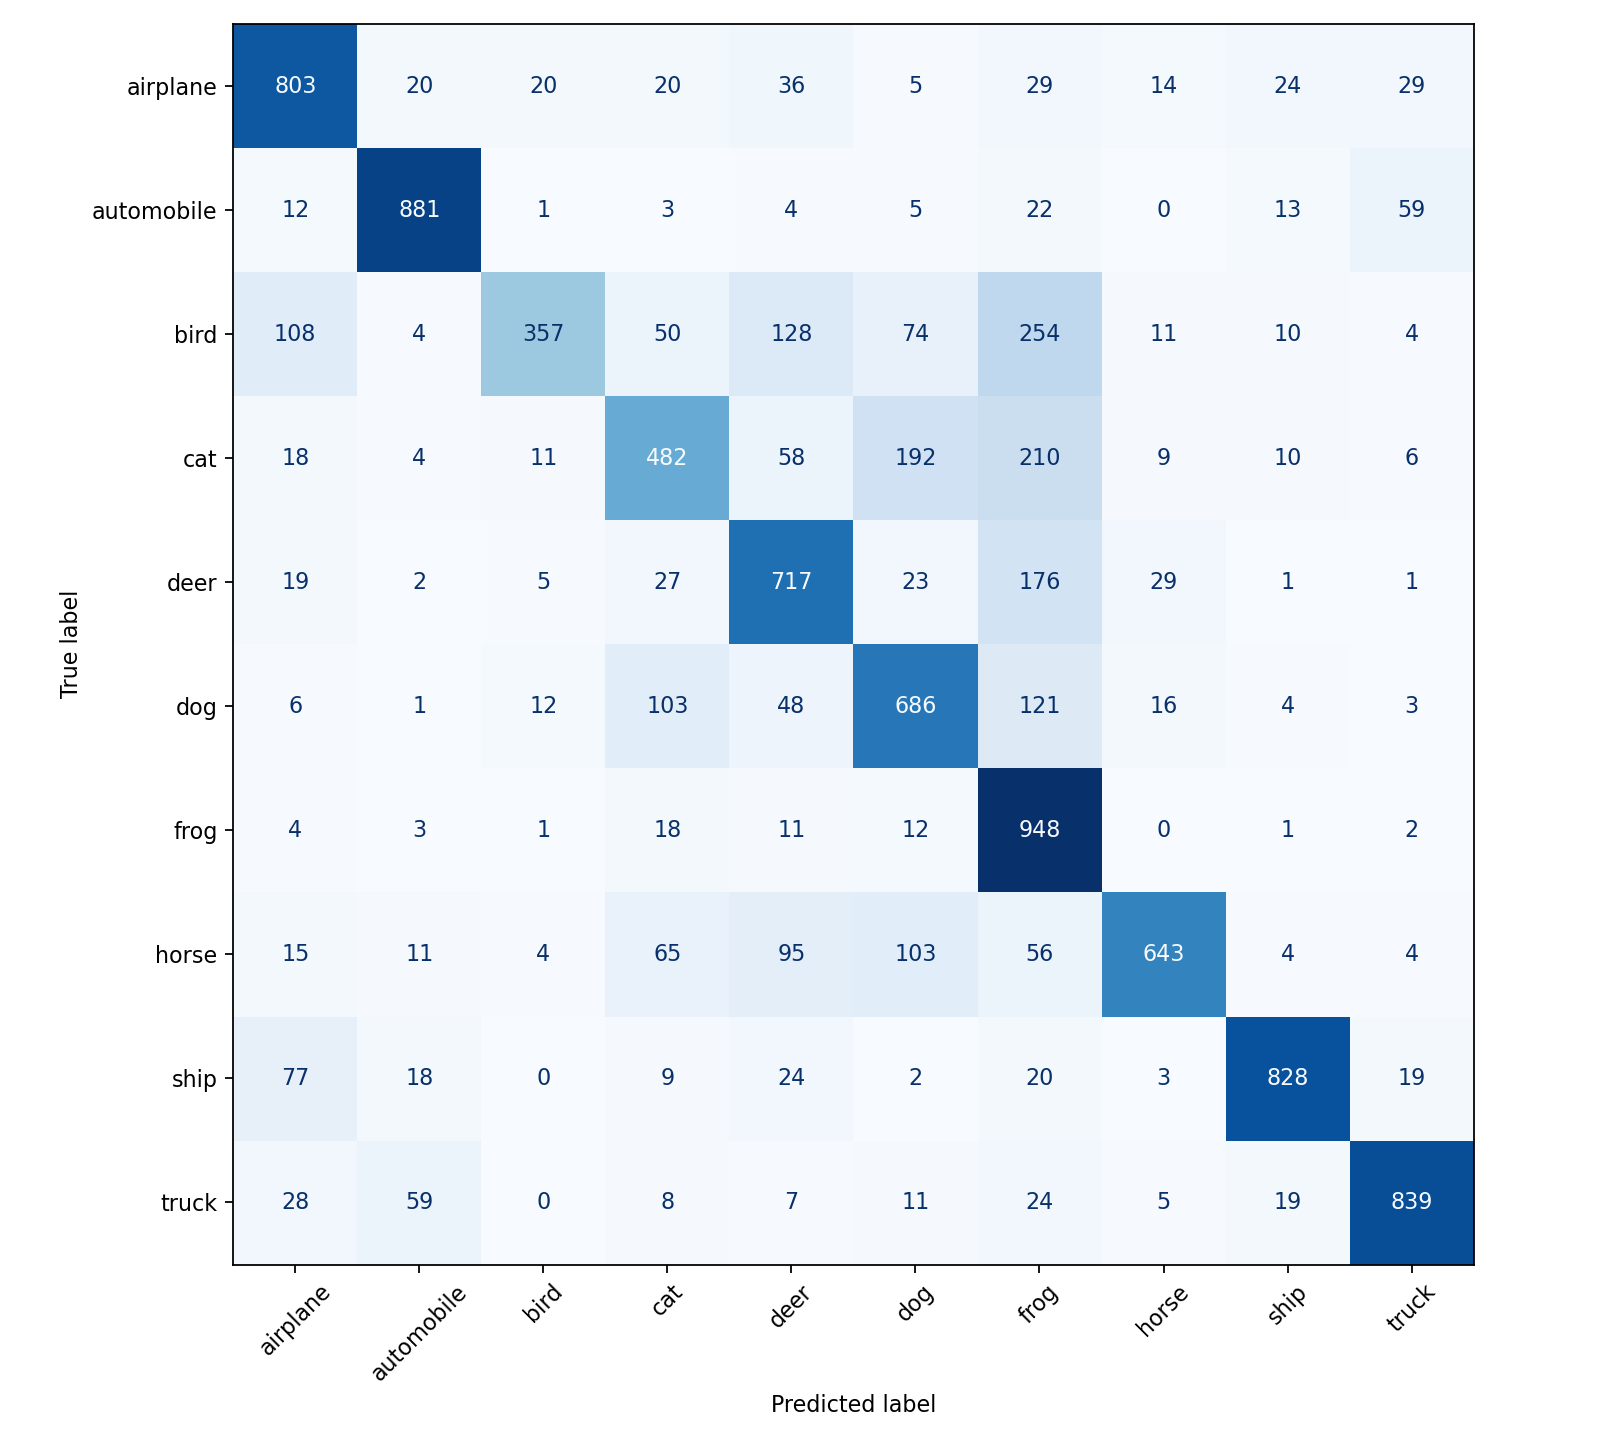

In [5]:
errors = {
    name: pd.read_csv(folder / 'validation_errors.csv') for name, folder in runs.items()
}
pair_counts = {
    name: rows.groupby(['actual', 'predicted']).size() for name, rows in errors.items()
}
selected_pairs = (
    pair_counts['CNN leve'].nlargest(5).index.union(pair_counts['CNN residual'].nlargest(5).index)
)
pairs = pd.DataFrame({
    name: counts.reindex(selected_pairs, fill_value=0) for name, counts in pair_counts.items()
})
pairs['Diferença'] = pairs['CNN residual'] - pairs['CNN leve']
display(pairs.sort_values('CNN residual', ascending=False).rename_axis(['Real', 'Prevista']))
baseline_wrong = set(errors['CNN leve']['validation_index'])
residual_wrong = set(errors['CNN residual']['validation_index'])
display(pd.Series({
    'Corrigidas pela residual': len(baseline_wrong - residual_wrong),
    'Novos erros da residual': len(residual_wrong - baseline_wrong),
    'Erros em ambos os modelos': len(baseline_wrong & residual_wrong),
}, name='Imagens').to_frame())
display(Image(filename=str(runs['CNN residual'] / 'figures/confusion_matrix.png')))

## O que mudou

- A residual ganhou **4,87 pontos percentuais de acurácia** e **5,25 pontos de F1 macro** na validação. Nas mesmas 10.000 imagens, corrigiu 1.415 erros da CNN leve e introduziu 928 erros, saldo de 487 acertos.
- Gato teve o maior ganho de F1, de **38,51% para 54,01%**. Seu recall passou de 30,50% para 48,20%, e os erros gato → cachorro caíram de 318 para 192.
- A residual passou a prever sapo com mais frequência. O recall de sapo subiu para 94,80%, enquanto a Precision caiu para 50,97%. Pássaro → sapo passou de 84 para 254 casos e o recall de pássaro caiu de 50,00% para 35,70%.
- A acurácia de validação da residual passou de 68,64% na época 6 para 53,66% na época 7 e 71,84% na época 8, enquanto a perda de treino caiu nas três épocas. O ganho final vem de uma rodada com uma única semente.

## Continuação da CNN residual até 60 épocas
A segunda sessão retomou o checkpoint da época 8 com os pesos e o otimizador salvos. Os callbacks foram reiniciados e a redução da taxa de aprendizado por platô permaneceu ativa. As duas avaliações usam os mesmos índices de treino e validação. O orçamento de 60 épocas permite observar a curva além do melhor checkpoint.

In [6]:
run60 = reports / 'residual_60_cpu'
meta60 = json.loads((run60 / 'run_metadata.json').read_text(encoding='utf-8'))
hist60 = pd.read_csv(run60 / 'history.csv')
hist60.index = pd.RangeIndex(1, len(hist60) + 1, name='Época')
best60 = meta60['best_epoch']
resumed_at = meta60['resumed_at_epoch']
with (
    np.load(root / 'data/processed/residual_cpu/split_indices.npz') as original_split,
    np.load(root / 'data/processed/residual_60_cpu/split_indices.npz') as continued_split,
):
    for key in ('train_idx', 'val_idx'):
        np.testing.assert_array_equal(original_split[key], continued_split[key])

duration_scores = {}
for budget, folder in [('8 épocas', runs['CNN residual']), ('60 épocas', run60)]:
    for split, file in [('Treino', 'train_metrics.json'), ('Validação', 'validation_metrics.json')]:
        metrics = json.loads((folder / file).read_text(encoding='utf-8'))
        duration_scores[budget, split] = {
            label: metrics[key] * 100 for key, label in metric_names.items()
        }
        duration_scores[budget, split]['Taxa de erro'] = (1 - metrics['accuracy']) * 100
duration_table = pd.DataFrame(duration_scores)
duration_table['Diferença na validação (p.p.)', '60 − 8'] = (
    duration_table['60 épocas', 'Validação'] - duration_table['8 épocas', 'Validação']
)
print(f'Continuação após a época {resumed_at} · {len(hist60)} épocas no histórico · checkpoint na época {best60}')
display(duration_table.round(2))

Continuação após a época 8 · 60 épocas no histórico · checkpoint na época 34


8 épocas           60 épocas            \
                  Treino Validação    Treino Validação   
Acurácia           74.07     71.84     94.90     85.52   
Precision macro    77.37     75.15     94.93     85.55   
Recall macro       74.07     71.84     94.90     85.52   
F1 macro           73.83     71.42     94.89     85.47   
Taxa de erro       25.93     28.16      5.10     14.48   

                Diferença na validação (p.p.)  
                                       60 − 8  
Acurácia                                13.68  
Precision macro                         10.41  
Recall macro                            13.68  
F1 macro                                14.05  
Taxa de erro                           -13.68

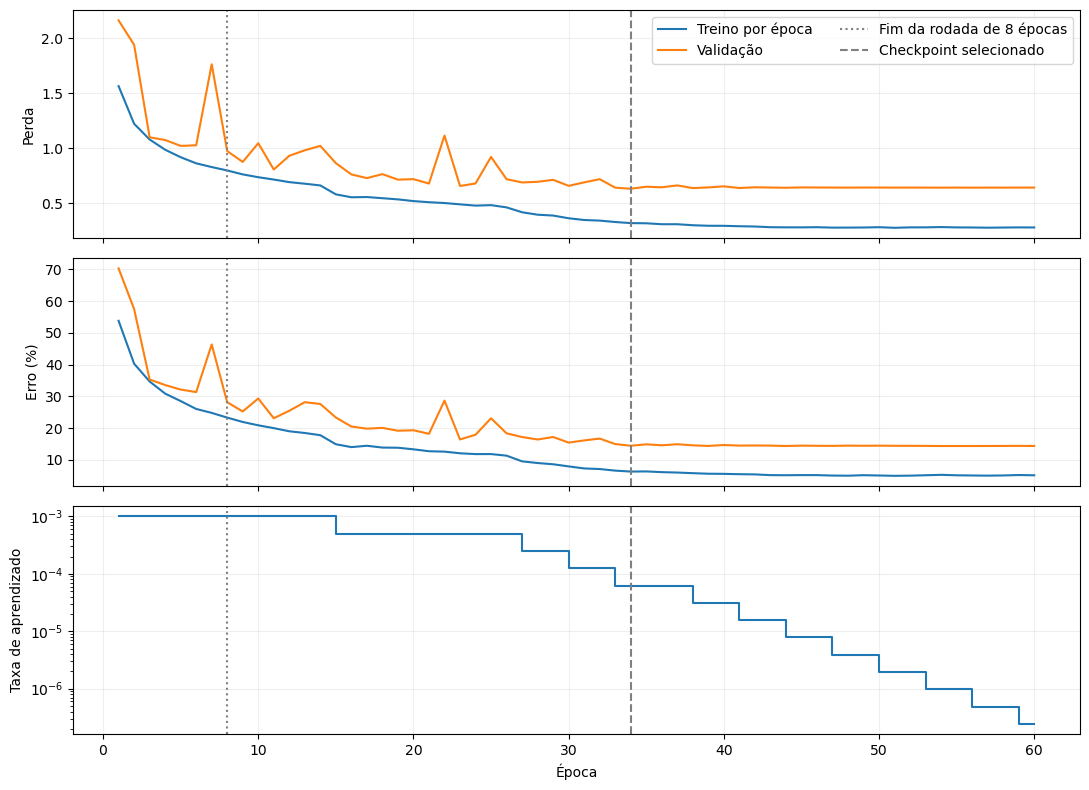

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, metric, ylabel in zip(axes[:2], ['loss', 'accuracy'], ['Perda', 'Erro (%)']):
    for prefix, label in [('', 'Treino por época'), ('val_', 'Validação')]:
        curve = hist60[f'{prefix}{metric}']
        ax.plot(hist60.index, (1 - curve) * 100 if metric == 'accuracy' else curve, label=label)
    ax.set_ylabel(ylabel)
axes[2].step(hist60.index, hist60.learning_rate, where='post')
axes[2].set(yscale='log', ylabel='Taxa de aprendizado', xlabel='Época')
for ax in axes:
    ax.axvline(resumed_at, color='gray', linestyle=':', label='Fim da rodada de 8 épocas')
    ax.axvline(best60, color='gray', linestyle='--', label='Checkpoint selecionado')
    ax.grid(alpha=0.2)
axes[0].legend(ncols=2)
fig.tight_layout()
plt.show()

8 épocas                 60 épocas                  \
           precision recall f1-score precision recall f1-score   
cat            61.40   48.2    54.01     71.92   70.7    71.31   
dog            61.64   68.6    64.93     77.93   75.9    76.90   
bird           86.86   35.7    50.60     83.37   78.7    80.97   
deer           63.56   71.7    67.39     89.69   81.8    85.56   
frog           50.97   94.8    66.29     82.11   92.7    87.08   
airplane       73.67   80.3    76.84     85.92   88.5    87.19   
horse          88.08   64.3    74.34     86.89   89.5    88.18   
truck          86.85   83.9    85.35     91.11   91.2    91.15   
automobile     87.84   88.1    87.97     91.57   94.5    93.01   
ship           90.59   82.8    86.52     95.03   91.7    93.33   

           Diferença (p.p.)  
                         F1  
cat                   17.30  
dog                   11.97  
bird                  30.36  
deer                  18.18  
frog                  20.79  
airplane              10.35  
horse                 13.84  
truck                  5.80  
automobile             5.04  
ship                   6.81

8 épocas  60 épocas
Real  Prevista                       
dog   cat              103        129
cat   dog              192        105
      frog             210         75
truck automobile        59         48
bird  frog             254         45
deer  frog             176         29
bird  deer             128         26

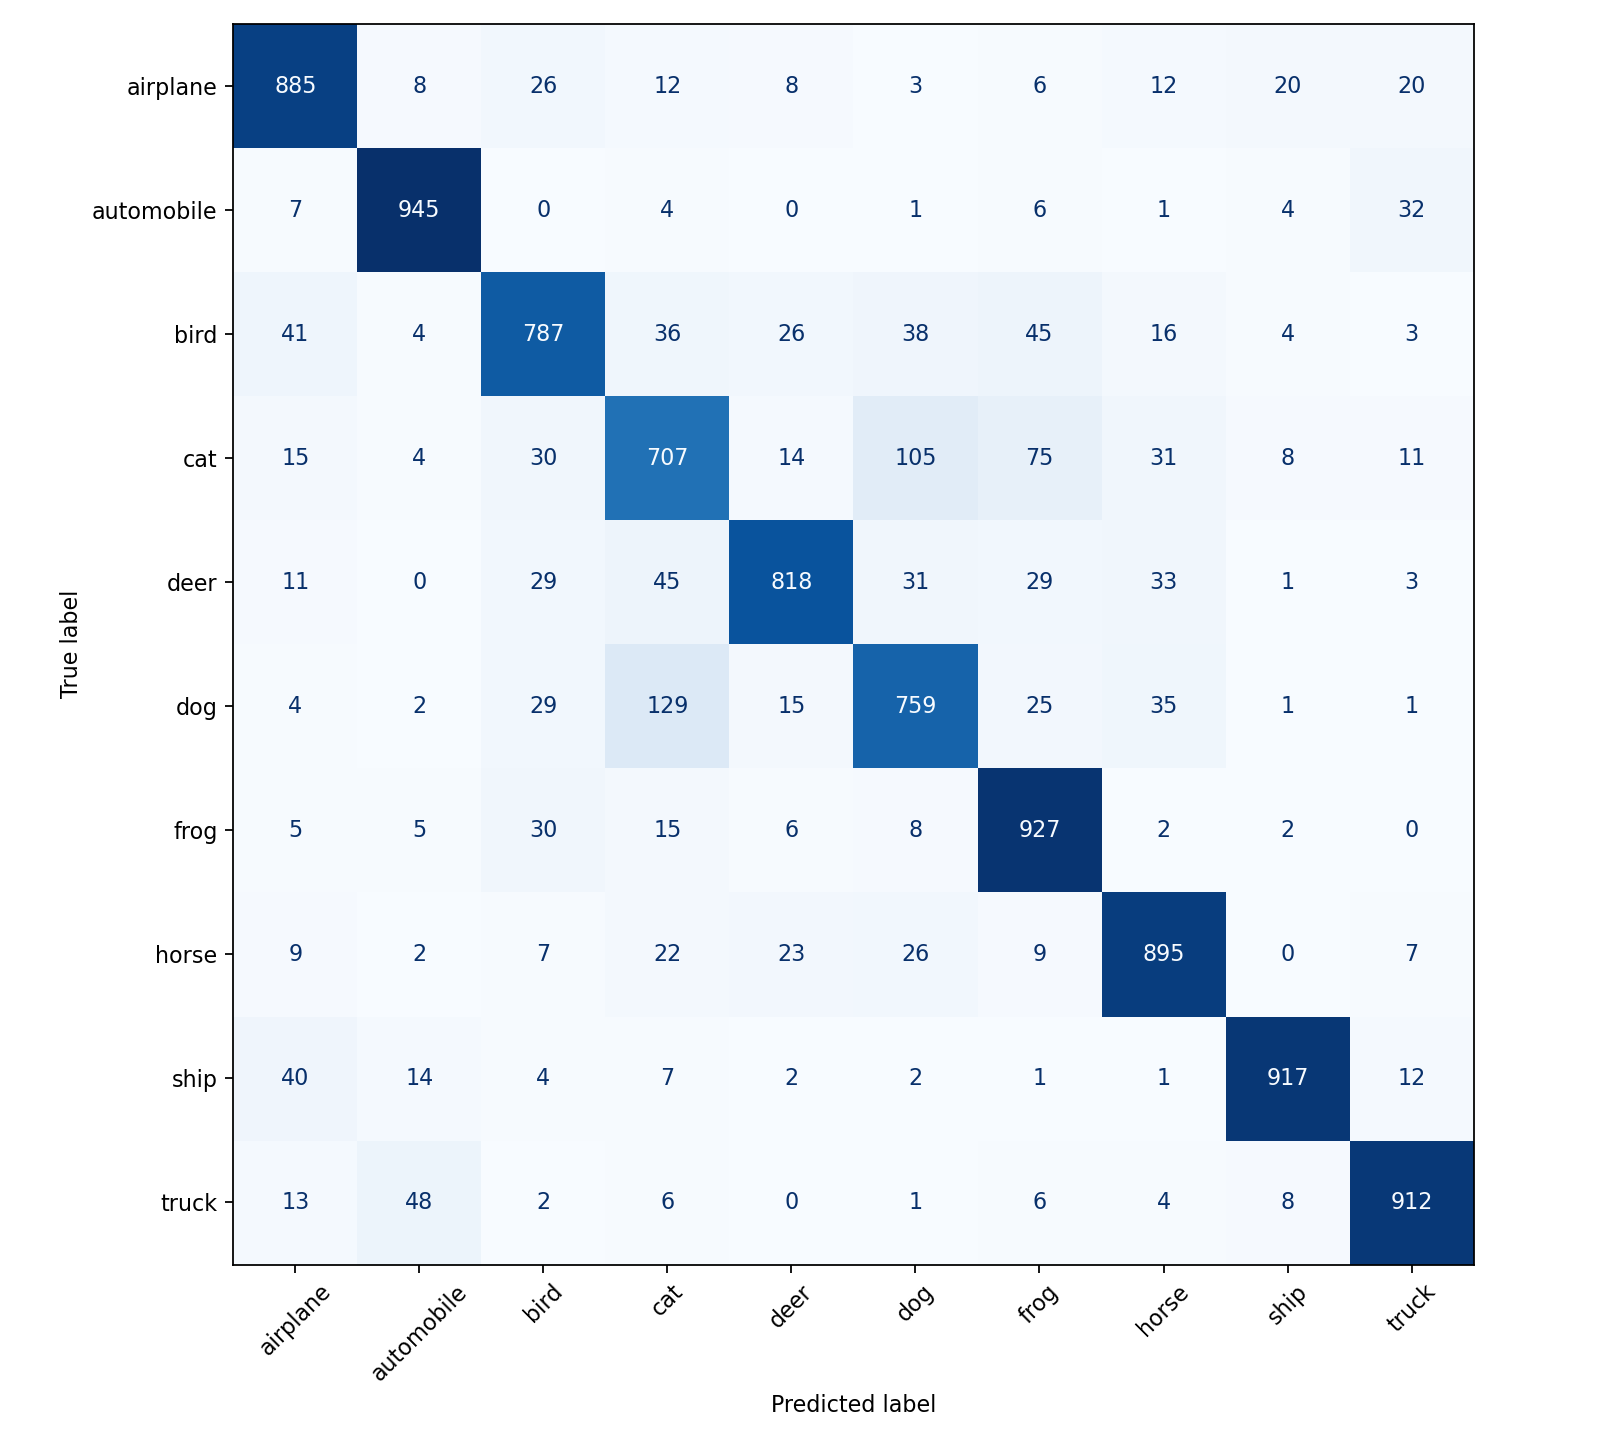

In [8]:
class60 = (
    pd.read_csv(run60 / 'validation_classification_report.csv', index_col=0)
    .drop(index=['accuracy', 'macro avg', 'weighted avg'])[class_columns]
)
duration_classes = pd.concat({'8 épocas': by_class['CNN residual'], '60 épocas': class60}, axis=1) * 100
duration_classes['Diferença (p.p.)', 'F1'] = (
    duration_classes['60 épocas', 'f1-score'] - duration_classes['8 épocas', 'f1-score']
)
display(duration_classes.sort_values(('60 épocas', 'f1-score')).round(2))

errors60 = pd.read_csv(run60 / 'validation_errors.csv')
pairs60 = errors60.groupby(['actual', 'predicted']).size()
pairs8 = pair_counts['CNN residual']
top = pairs8.nlargest(5).index.union(pairs60.nlargest(5).index)
display(pd.DataFrame({
    '8 épocas': pairs8.reindex(top, fill_value=0),
    '60 épocas': pairs60.reindex(top, fill_value=0),
}).sort_values('60 épocas', ascending=False).rename_axis(['Real', 'Prevista']))
display(Image(filename=str(run60 / 'figures/confusion_matrix.png')))

### Efeito de aumentar o orçamento

- A validação passou de **2.816 para 1.448 erros** nas mesmas 10.000 imagens. O F1 macro subiu de **71,42% para 85,47%**.
- Pássaro teve o maior ganho de F1, de **50,60% para 80,97%**, e os erros pássaro → sapo caíram de 254 para 45. Cachorro → gato passou de 103 para 129 casos e virou a maior confusão.
- A época **34** teve a menor perda de validação (**0,6311**). A época 60 teve acurácia de validação de 85,59% e perda de 0,6419. A curva de erro se estabilizou perto de 14,5% enquanto a perda de treino continuou caindo.